# Fine Tuning

## Author - Tanner Hume

This file is a modified version of a tutorial by geeksforgeeks ([Fine-tuning BERT model for Sentiment Analysis](https://www.geeksforgeeks.org/nlp/fine-tuning-bert-model-for-sentiment-analysis/)
) about fine-tuning BERT. The turotial covers taking the existing model [Bert Base Uncased](https://huggingface.co/google-bert/bert-base-uncased) and adjusting all of BERTs 110M paramaters, alongside its classification head, to better classify the GoEmotions dataset.

The tutorial ran on a dataset of IMDB movie reviews labeled either 'positive' or 'negative', and the original purpose of the model here was to run sentiment predictions on reviews. Here, GoEmotions has 28 different classes of text, so the code here had to be modified to support multi-class classification.

On top of that, a validation step to determine the classification theshold for individual emotions, because some emotions (Grief, Relief, Pride, and Nervousness) are extremely uncommon and need to have very low thesholds to be detected.

### AI Usage Disclousre

I do not have much experience with machine learning in code beyond what we have done in class, so essentially numpy work with matricies, sklearn packages, and intermediate Python. AI (Specifically Claude Code Sonnet and Opus 5.5) was used to help modify the tutorial as well as to teach me several important programing concepts in order to implement everything here.


In [ ]:
%pip install -q transformers torch scikit-learn pandas datasets matplotlib

In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm  # progress bars (widget in Jupyter/Colab, text in a terminal)
from transformers import (
    BertTokenizerFast,
    BertModel,
    BertForSequenceClassification,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
    set_seed
)

# Only import load_dataset here: importing `Dataset` from `datasets` would
# overwrite torch's Dataset class imported above
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import classification_report, f1_score, roc_auc_score, roc_curve

In [ ]:
RANDOM_SEED = 67
# Method from transformers that ensures that everything runs the same every time
set_seed(RANDOM_SEED)

### Loading the dataset


In [ ]:
ds = load_dataset("google-research-datasets/go_emotions", "simplified")
print(ds)  # a DatasetDict with 'train', 'validation', and 'test' splits

# Transforms the huggingface dataset into a pandas dataset while ignoring splits.
# I wanted to write this in such a way that it isn't dependent on the prexisting training-test-validation splits.
df = pd.concat(
    [ds[split].to_pandas() for split in ds.keys()],
    ignore_index=True
)

# The 28 emotion names
label_names = ds['train'].features['labels'].feature.names
print(df.head())
print(df.shape)

# Each row's 'labels' value is a list (a comment can have several emotions),
# so explode the lists before counting how often each emotion appears
print(df['labels'].explode().map(lambda i: label_names[i]).value_counts())

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})
                                                text labels       id
0  My favourite food is anything I didn't have to...   [27]  eebbqej
1  Now if he does off himself, everyone will thin...   [27]  ed00q6i
2                     WHY THE FUCK IS BAYLESS ISOING    [2]  eezlygj
3                        To make her feel threatened   [14]  ed7ypvh
4                             Dirty Southern Wankers    [3]  ed0bdzj
(54263, 3)
labels
neutral           17772
admiration         5122
approval           3687
gratitude          3372
annoyance          3093
amusement          2895
curiosity          2723
disapproval        2581
love               2576
optimism           1976
anger              19

I am going to be completely honest, I have no idea why the content of the first lines of the dataset are extremely negative and rude. The dataset is sourced from reddit comments so it is reasonable that some are toxic, it is just an unfortunate coincidence that the dataset is ordered like this


### Converting the emotion labels to multi-hot vectors

GoEmotions is multi-label: each comment has a list of one or more emotion ids (e.g. `[2, 27]`). We turn each list into a vector of 28 zeros and ones in a multi-hot encoding, with a 1 at every emotion the comment has. The values are stored as floats because the multi-label loss function (`BCEWithLogitsLoss`) expects float targets.


In [ ]:
num_labels = len(label_names)  # 28

# classes=... fixes the column order so column i is always label id i
mlb = MultiLabelBinarizer(classes=list(range(num_labels)))
label_matrix = mlb.fit_transform(df['labels']).astype(np.float32)

print(label_matrix.shape)  # (number of comments, 28)

# Check one example: its label list and its multi-hot vector
print(df['labels'][0], '->', label_matrix[0])

# How many comments have more than one emotion
print("Comments with multiple labels:", (label_matrix.sum(axis=1) > 1).sum())

(54263, 28)
[27] -> [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 1.]
Comments with multiple labels: 8817


### Splitting into train / validation / test sets


This program ignores the premade splits that the dataset has by default and performs a 80/10/10 split between the Training, Validation, and Test sets.


In [ ]:
train_text, temp_text, train_labels, temp_labels = train_test_split(
    df['text'],
    label_matrix,
    test_size=0.20,
    random_state=RANDOM_SEED
)

val_text, test_text, val_labels, test_labels = train_test_split(
    temp_text,
    temp_labels,
    test_size=0.50,
    random_state=RANDOM_SEED
)



print("Training samples:", len(train_text))
print("Validation samples:", len(val_text))
print("Test samples:", len(test_text))

Training samples: 43410
Validation samples: 5426
Test samples: 5427


### Loading BERT

`num_labels=28` gives the classifier one output per emotion. `problem_type="multi_label_classification"` makes the model use `BCEWithLogitsLoss`, which treats each emotion as its own yes/no question, instead of `CrossEntropyLoss`, which forces exactly one class per example.


In [ ]:
tokenizer = BertTokenizerFast.from_pretrained(
    'bert-base-uncased'
)

model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=num_labels,
    problem_type="multi_label_classification",
    # Optional: lets the model's config show emotion names instead of LABEL_0, LABEL_1, ...
    id2label={i: name for i, name in enumerate(label_names)},
    label2id={name: i for i, name in enumerate(label_names)}
)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
max_length = 64

### Making a dataset class


In [ ]:
class GoEmotionsDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts = texts.tolist()    # pandas Series -> list of strings
        self.labels = labels.tolist()  # numpy array -> list of 28-float lists
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = self.tokenizer(
            self.texts[index],
            truncation=True,
            max_length=self.max_length
        )

        # A list of 28 floats (the multi-hot vector), not a single integer
        encoding['labels'] = self.labels[index]

        return encoding

### Formalizing the datasets


In [ ]:
train_dataset = GoEmotionsDataset(
    train_text,
    train_labels,
    tokenizer,
    max_length
)

val_dataset = GoEmotionsDataset(
    val_text,
    val_labels,
    tokenizer,
    max_length
)

test_dataset = GoEmotionsDataset(
    test_text,
    test_labels,
    tokenizer,
    max_length
)

# Sanity check: labels should be a list of 28 floats
print(train_dataset[0]['labels'])

[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


### Tokenizing the data


In [ ]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

In [ ]:
train_dataloader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    collate_fn=data_collator
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=16,
    collate_fn=data_collator
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=16,
    collate_fn=data_collator
)

### Prepares cuda if available


In [ ]:
device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

model = model.to(device)

print("Using device:", device)

Using device: cuda


### Creates an optimizer for BERT paramaters


Implements the AdamW algorithm


In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=5e-5
)

### Learning-rate schedule

Instead of just using a single learning rate for the whole run, the learning rate follows a linear warmup and decay:

- **Warmup (first 10% of steps):** the learning rate climbs from 0 up to 5e-5. The classifier layer starts out random, so its early gradients are large and noisy; starting small keeps those first updates from disturbing BERT's pretrained weights.
- **Decay (remaining steps):** the learning rate falls in a straight line back to 0 by the final step, so the last updates are small refinements.

`scheduler.step()` is called once per batch in the training loop. The schedule needs to know the total number of steps up front, which is why `epochs` is set here.


In [ ]:
epochs = 4

# One optimizer step per batch, for every epoch
total_steps = len(train_dataloader) * epochs

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

print("Total training steps:", total_steps)
print("Warmup steps:", int(0.1 * total_steps))

Total training steps: 10856
Warmup steps: 1085


### Evaluation helpers

`evaluate()` runs the model over a dataloader without training it and returns four things: the average loss, the 0/1 predictions, the true labels, and the raw sigmoid probabilities. The training loop calls it on the validation set after every epoch, and the evaluation cells at the end reuse it.

An emotion is predicted when its probability is above the threshold. `threshold` can be a single number used for every emotion (the default below), or an array of 28 numbers with one threshold per emotion.

`tune_thresholds()` produces that array. For each emotion separately it tries thresholds from 0.05 to 0.95 and keeps whichever gives that emotion the highest F1. An emotion keeps the default threshold unless another value does strictly better. The training loop calls it after every epoch, so each epoch is scored with thresholds suited to that epoch's model.


In [ ]:
threshold = 0.3  # default threshold, the starting point for every emotion before tuning


def evaluate(model, dataloader, threshold):

    model.eval()  # turn off dropout

    # Works for one number or an array of 28: torch compares each column of
    # `probs` against its own threshold (this is called broadcasting)
    thresholds = torch.as_tensor(threshold, dtype=torch.float32, device=device)

    total_loss = 0
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():  # no gradients needed, which saves memory and time

        for batch in dataloader:

            labels = batch['labels']

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(**batch)
            total_loss += outputs.loss.item()

            # Sigmoid turns each logit into a 0-1 probability, independently per emotion
            probs = torch.sigmoid(outputs.logits)
            predictions = (probs > thresholds).int()

            all_preds.append(
                predictions.cpu().numpy()
            )

            all_labels.append(
                labels.numpy().astype(int)
            )

            all_probs.append(
                probs.cpu().numpy()
            )

    avg_loss = total_loss / len(dataloader)

    # Stack the per-batch arrays into one (num_samples, 28) array each
    return (
        avg_loss,
        np.vstack(all_preds),
        np.vstack(all_labels),
        np.vstack(all_probs)
    )


# Candidate thresholds tried for each emotion: 0.05, 0.10, ..., 0.95
candidate_thresholds = np.round(np.arange(0.05, 1.0, 0.05), 2)


def tune_thresholds(labels, probs, default_threshold):
    """Pick, for each emotion separately, the threshold that gives it the best F1.

    Returns three arrays of length 28: the chosen thresholds, each emotion's F1
    at the default threshold, and each emotion's F1 at its chosen threshold.
    """
    n = labels.shape[1]
    thresholds = np.full(n, default_threshold)  # start every emotion at the default
    default_f1 = np.zeros(n)
    tuned_f1 = np.zeros(n)

    for i in range(n):

        true_i = labels[:, i]   # 0/1 labels for emotion i
        probs_i = probs[:, i]   # model's probabilities for emotion i

        # F1 for this emotion with the default threshold
        default_f1[i] = f1_score(true_i, (probs_i > default_threshold).astype(int), zero_division=0)
        tuned_f1[i] = default_f1[i]

        # Switch to a candidate threshold only if it beats the best F1 so far
        for t in candidate_thresholds:
            f1 = f1_score(true_i, (probs_i > t).astype(int), zero_division=0)
            if f1 > tuned_f1[i]:
                tuned_f1[i] = f1
                thresholds[i] = t

    return thresholds, default_f1, tuned_f1

### Training the model

After every epoch the model is scored on the validation set twice: once with the single default threshold, and once with thresholds re-tuned for that epoch's model. The tuned score decides which epoch is best, because tuned thresholds are what the final model is actually evaluated with.

Whenever an epoch beats the best score so far, a copy of its weights and thresholds is kept. After the last epoch those weights are loaded back into the model, so everything below uses the best epoch rather than the last one. Validation loss rises after a couple of epochs (overfitting), so the last epoch is often not the best.

**Selection metric.** `selection_metric = 'macro'` picks the epoch with the best tuned Macro F1. Macro F1 gives all 28 emotions equal weight, so it rewards getting the rare emotions right, which is the point of tuning thresholds per emotion. It is also the main metric reported in the GoEmotions paper. Micro F1 is dominated by the most common emotions (neutral alone is about 29% of the labels). Set `selection_metric = 'micro'` to choose by that instead.


In [ ]:
scaler = torch.amp.GradScaler(
    'cuda',
    enabled=(device.type == 'cuda')
)

# Which tuned validation score decides the best epoch: 'macro' or 'micro'
selection_metric = 'macro'

best_score = -1.0
best_epoch = None
best_state = None        # copy of the best epoch's weights
best_thresholds = None   # the 28 thresholds tuned for the best epoch

for epoch in range(epochs):

    model.train()
    total_loss = 0

    # tqdm wraps the dataloader and draws a progress bar as batches are used up
    progress_bar = tqdm(
        train_dataloader,
        desc=f"Epoch {epoch + 1}/{epochs}"
    )

    for batch in progress_bar:

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad()

        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == 'cuda')
        ):
            outputs = model(**batch)
            loss = outputs.loss

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Move the learning rate one step along the warmup/decay schedule
        scheduler.step()

        batch_loss = loss.item()
        total_loss += batch_loss

        # Show the current batch loss and learning rate next to the bar
        progress_bar.set_postfix(
            loss=f"{batch_loss:.4f}",
            lr=f"{scheduler.get_last_lr()[0]:.2e}"
        )

    avg_train_loss = total_loss / len(train_dataloader)

    # Check how the model does on the validation set after every epoch.
    # If validation loss starts rising while training loss keeps falling,
    # the model is starting to overfit.
    val_loss, val_preds, val_labels_list, val_probs = evaluate(
        model, val_dataloader, threshold
    )

    micro_f1 = f1_score(val_labels_list, val_preds, average='micro', zero_division=0)
    macro_f1 = f1_score(val_labels_list, val_preds, average='macro', zero_division=0)

    # Re-tune each emotion's threshold for this epoch's model, then score with them
    epoch_thresholds, _, _ = tune_thresholds(val_labels_list, val_probs, threshold)
    tuned_preds = (val_probs > epoch_thresholds).astype(int)

    tuned_micro_f1 = f1_score(val_labels_list, tuned_preds, average='micro', zero_division=0)
    tuned_macro_f1 = f1_score(val_labels_list, tuned_preds, average='macro', zero_division=0)

    print(
        f"Epoch {epoch + 1}/{epochs} - "
        f"Train Loss: {avg_train_loss:.3f} | "
        f"Val Loss: {val_loss:.3f}\n"
        f"  Default threshold ({threshold}): "
        f"Val Micro F1: {micro_f1:.3f} | Val Macro F1: {macro_f1:.3f}\n"
        f"  Tuned thresholds:          "
        f"Val Micro F1: {tuned_micro_f1:.3f} | Val Macro F1: {tuned_macro_f1:.3f}"
    )

    score = tuned_macro_f1 if selection_metric == 'macro' else tuned_micro_f1

    if score > best_score:
        best_score = score
        best_epoch = epoch + 1
        best_thresholds = epoch_thresholds
        # Copy the weights to CPU memory so later epochs can't overwrite them
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        print(f"  -> New best epoch (tuned {selection_metric} F1: {score:.3f})")

# Put the best epoch's weights back into the model for everything below
model.load_state_dict(best_state)
print(
    f"\nUsing weights from epoch {best_epoch} "
    f"(tuned validation {selection_metric} F1: {best_score:.3f})"
)

Epoch 1/4:   0%|          | 0/2714 [00:00<?, ?it/s]

Epoch 1/4 - Train Loss: 0.153 | Val Loss: 0.094
  Default threshold (0.3): Val Micro F1: 0.570 | Val Macro F1: 0.365
  Tuned thresholds:          Val Micro F1: 0.557 | Val Macro F1: 0.431
  -> New best epoch (tuned macro F1: 0.431)


Epoch 2/4:   0%|          | 0/2714 [00:00<?, ?it/s]

Epoch 2/4 - Train Loss: 0.083 | Val Loss: 0.086
  Default threshold (0.3): Val Micro F1: 0.595 | Val Macro F1: 0.456
  Tuned thresholds:          Val Micro F1: 0.596 | Val Macro F1: 0.498
  -> New best epoch (tuned macro F1: 0.498)


Epoch 3/4:   0%|          | 0/2714 [00:00<?, ?it/s]

Epoch 3/4 - Train Loss: 0.065 | Val Loss: 0.089
  Default threshold (0.3): Val Micro F1: 0.588 | Val Macro F1: 0.482
  Tuned thresholds:          Val Micro F1: 0.591 | Val Macro F1: 0.508
  -> New best epoch (tuned macro F1: 0.508)


Epoch 4/4:   0%|          | 0/2714 [00:00<?, ?it/s]

Epoch 4/4 - Train Loss: 0.048 | Val Loss: 0.095
  Default threshold (0.3): Val Micro F1: 0.575 | Val Macro F1: 0.484
  Tuned thresholds:          Val Micro F1: 0.582 | Val Macro F1: 0.514
  -> New best epoch (tuned macro F1: 0.514)

Using weights from epoch 4 (tuned validation macro F1: 0.514)


### Evaluating the model

With multi-label output, we apply a sigmoid to each of the 28 logits to get an independent probability per emotion, and predict every emotion whose probability is above a threshold. Evaluation happens in three steps:

1. A validation report using the single default `threshold` for every emotion.
2. Tuning a separate threshold for each emotion on the validation set.
3. A test report using the tuned thresholds, compared against the default.


In [ ]:
# Full per-emotion report on the validation set, using the default threshold for every emotion
val_loss, val_preds, val_labels_list, val_probs = evaluate(
    model, val_dataloader, threshold
)

print(
    classification_report(
        val_labels_list,
        val_preds,
        target_names=label_names,
        zero_division=0  # rare emotions may never be predicted; report 0 instead of warning
    )
)

                precision    recall  f1-score   support

    admiration       0.66      0.74      0.70       509
     amusement       0.72      0.89      0.80       296
         anger       0.46      0.62      0.53       175
     annoyance       0.32      0.40      0.36       303
      approval       0.34      0.40      0.37       376
        caring       0.41      0.48      0.44       135
     confusion       0.42      0.39      0.40       173
     curiosity       0.48      0.64      0.55       286
        desire       0.50      0.65      0.57        81
disappointment       0.28      0.28      0.28       149
   disapproval       0.38      0.43      0.40       264
       disgust       0.46      0.52      0.49       104
 embarrassment       0.59      0.54      0.57        35
    excitement       0.46      0.53      0.49        93
          fear       0.55      0.63      0.59        84
     gratitude       0.91      0.89      0.90       337
         grief       0.00      0.00      0.00  

### Tuning a threshold for each emotion

A single threshold of 0.3 works for common emotions, but the model rarely gives rare emotions (grief, pride, relief, ...) a probability that high, even for comments that really do express them. So those emotions are almost never predicted and their F1 is 0.

The training loop already tuned thresholds for every epoch and kept the ones from the best epoch. This cell runs `tune_thresholds()` again on the restored best model, which gives the same thresholds, and prints them in a table next to each emotion's F1 before and after tuning.

The thresholds are chosen on the validation set, never the test set, avoiding data leakage. They are a setting we pick by looking at results, like the learning rate, so choosing them on the test set would make the test score look better than it really is. The best epoch is also chosen on the validation set. For both reasons the "tuned" validation scores below are a bit optimistic since they are scoring the data that the hyperparamaters are optimized for; the test set results afterwards are the honest measure.


In [ ]:
best_thresholds, default_f1, tuned_f1 = tune_thresholds(
    val_labels_list, val_probs, threshold
)

threshold_table = pd.DataFrame({
    'emotion': label_names,
    'val examples': val_labels_list.sum(axis=0),
    'threshold': best_thresholds,
    'F1 (default)': default_f1.round(2),
    'F1 (tuned)': tuned_f1.round(2),
}).sort_values('val examples', ascending=False)

print(threshold_table.to_string(index=False))

# Macro F1 is the plain average of the 28 per-emotion F1 scores
print(
    f"\nValidation Macro F1: {default_f1.mean():.3f} (default) "
    f"-> {tuned_f1.mean():.3f} (tuned)"
)

       emotion  val examples  threshold  F1 (default)  F1 (tuned)
       neutral          1831       0.15          0.63        0.66
    admiration           509       0.45          0.70        0.70
      approval           376       0.45          0.37        0.38
     gratitude           337       0.75          0.90        0.92
     annoyance           303       0.15          0.36        0.37
     amusement           296       0.30          0.80        0.80
     curiosity           286       0.10          0.55        0.56
   disapproval           264       0.15          0.40        0.41
          love           234       0.35          0.77        0.77
      optimism           199       0.40          0.58        0.59
         anger           175       0.30          0.53        0.53
     confusion           173       0.20          0.40        0.44
           joy           172       0.35          0.63        0.63
       sadness           158       0.25          0.53        0.54
disappoint

In [ ]:
# Evaluate the test set with the tuned per-emotion thresholds
test_loss, test_preds, test_labels_list, test_probs = evaluate(
    model, test_dataloader, best_thresholds
)

# For comparison: the same test probabilities with the single default threshold
test_preds_default = (test_probs > threshold).astype(int)

print(f"Test Loss: {test_loss:.3f}\n")

for name, preds in [
    (f"Default threshold ({threshold})", test_preds_default),
    ("Tuned thresholds", test_preds),
]:
    micro_f1 = f1_score(test_labels_list, preds, average='micro', zero_division=0)
    macro_f1 = f1_score(test_labels_list, preds, average='macro', zero_division=0)
    print(f"{name:28s} Test Micro F1: {micro_f1:.3f} | Test Macro F1: {macro_f1:.3f}")

Test Loss: 0.094

Default threshold (0.3)      Test Micro F1: 0.589 | Test Macro F1: 0.495
Tuned thresholds             Test Micro F1: 0.587 | Test Macro F1: 0.510


As you can see here, tuning the thresholds here results in a slightly higher Macro score and a slightly lower Micro score. This means the model performs slightly worse overall, but it also performs significantly better in rarer categories, never getting an F1 score of 0 in any emotion and still having decent performance overall.

Personally, I think the slight hit to overall performance is worth being able to pick up on more subtle and rare emotions like grief and relief


### ROC curves and AUC

A ROC curve shows how well the model's probabilities separate comments that have an emotion from comments that don't. As the threshold sweeps from 1 down to 0, it plots the **true positive rate** (share of real examples the model catches) against the **false positive rate** (share of non-examples it wrongly flags). **AUC** is the area under that curve: 1.0 means every real example gets a higher probability than every non-example, and 0.5 is random guessing.

Because ROC covers every possible threshold, it does not depend on the 0.3 default or the tuned thresholds. It measures how well the model _ranks_ comments, while F1 measures the yes/no decisions at one threshold.

GoEmotions is multi-label, so there is one ROC curve per emotion. 28 curves on one chart would be unreadable, so this section shows:

1. A table of each emotion's AUC.
2. The **micro-average** curve, which pools every comment–emotion pair into one big yes/no problem (so common emotions dominate), and the **macro-average** curve, which averages the 28 per-emotion curves with equal weight.
3. Each emotion's AUC as a sorted chart, with its number of test examples.

**Caveat:** for rare emotions almost every comment is a negative, so the false positive rate stays small even when the model wrongly flags many comments. ROC AUC can therefore look high for emotions whose precision is poor. The per-emotion F1 scores above are the better guide to how useful the actual predictions are.


In [ ]:
# AUC for each emotion, plus micro and macro averages, on the test set.
# These use the raw probabilities, so no threshold is involved.
per_emotion_auc = roc_auc_score(test_labels_list, test_probs, average=None)
micro_auc = roc_auc_score(test_labels_list, test_probs, average='micro')
macro_auc = roc_auc_score(test_labels_list, test_probs, average='macro')

auc_table = pd.DataFrame({
    'emotion': label_names,
    'test examples': test_labels_list.sum(axis=0),
    'AUC': per_emotion_auc.round(3),
}).sort_values('AUC', ascending=False)

print(auc_table.to_string(index=False))
print(f"\nTest Micro AUC: {micro_auc:.3f} | Test Macro AUC: {macro_auc:.3f}")

       emotion  test examples   AUC
     gratitude            324 0.986
          love            249 0.985
     amusement            296 0.974
       remorse             65 0.972
      surprise            126 0.954
     curiosity            278 0.954
       sadness            174 0.948
          fear             80 0.947
        desire             61 0.946
         anger            199 0.942
    admiration            517 0.941
           joy            198 0.940
       disgust            120 0.928
     confusion            173 0.928
   nervousness             23 0.919
      optimism            190 0.912
        relief             15 0.909
        caring            138 0.903
    excitement            101 0.890
 embarrassment             44 0.886
disappointment            170 0.875
   disapproval            252 0.875
     annoyance            330 0.865
       neutral           1749 0.836
      approval            350 0.814
   realization            130 0.814
         pride             1

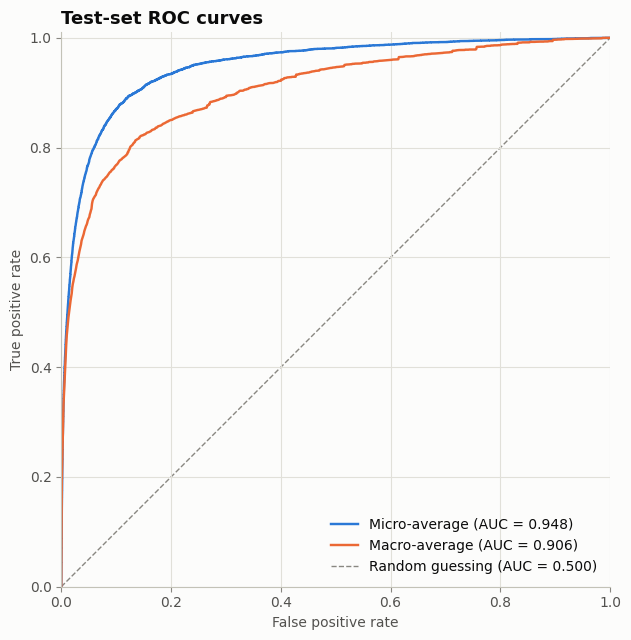

In [ ]:
# Colors and styling shared by the charts below
COLORS = {
    'surface': '#fcfcfb',
    'ink': '#0b0b0b',
    'ink_secondary': '#52514e',
    'muted': '#898781',
    'grid': '#e1e0d9',
    'axis': '#c3c2b7',
    'micro': '#2a78d6',  # blue
    'macro': '#eb6834',  # orange
}

chart_style = {
    'figure.facecolor': COLORS['surface'],
    'axes.facecolor': COLORS['surface'],
    'axes.edgecolor': COLORS['axis'],
    'axes.labelcolor': COLORS['ink_secondary'],
    'axes.titlecolor': COLORS['ink'],
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': COLORS['grid'],
    'grid.linewidth': 0.8,
    'xtick.color': COLORS['muted'],
    'ytick.color': COLORS['muted'],
    'xtick.labelcolor': COLORS['ink_secondary'],
    'ytick.labelcolor': COLORS['ink_secondary'],
    'legend.frameon': False,
    'legend.labelcolor': COLORS['ink'],
}

# Micro-average: flatten every (comment, emotion) pair into one long yes/no list
micro_fpr, micro_tpr, _ = roc_curve(test_labels_list.ravel(), test_probs.ravel())

# Macro-average: compute each emotion's curve, put them all on the same grid of
# false positive rates, and average the true positive rates with equal weight
fpr_grid = np.linspace(0, 1, 1001)
macro_tpr = np.zeros_like(fpr_grid)

for i in range(num_labels):
    fpr_i, tpr_i, _ = roc_curve(test_labels_list[:, i], test_probs[:, i])
    macro_tpr += np.interp(fpr_grid, fpr_i, tpr_i)

macro_tpr /= num_labels
macro_tpr[0] = 0.0  # every curve starts at (0, 0)

with plt.rc_context(chart_style):
    fig, ax = plt.subplots(figsize=(6.5, 6.5))

    ax.plot(micro_fpr, micro_tpr, color=COLORS['micro'], linewidth=1.75,
            label=f'Micro-average (AUC = {micro_auc:.3f})')
    ax.plot(fpr_grid, macro_tpr, color=COLORS['macro'], linewidth=1.75,
            label=f'Macro-average (AUC = {macro_auc:.3f})')
    ax.plot([0, 1], [0, 1], color=COLORS['muted'], linewidth=1, linestyle='--',
            label='Random guessing (AUC = 0.500)', zorder=1)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.01)
    ax.set_aspect('equal')
    ax.set_xlabel('False positive rate')
    ax.set_ylabel('True positive rate')
    ax.set_title('Test-set ROC curves')
    ax.legend(loc='lower right')
    fig.tight_layout()
    plt.show()

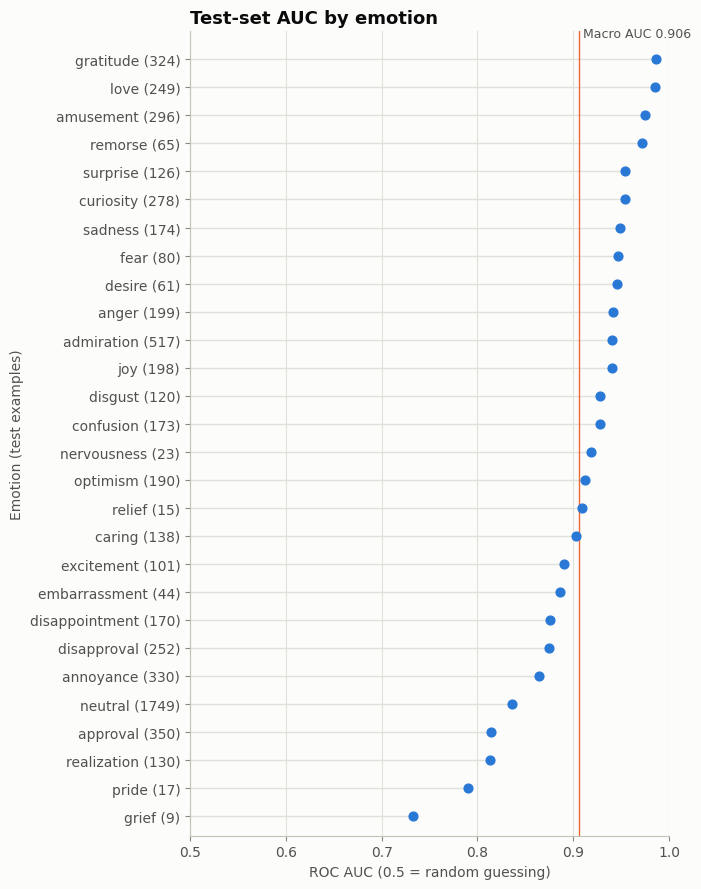

In [ ]:
# Each emotion's AUC as a dot, sorted so the highest AUC is at the top.
# The number in brackets is how many test comments have that emotion.
order = np.argsort(per_emotion_auc)
test_counts = test_labels_list.sum(axis=0)
row_labels = [f"{label_names[i]} ({test_counts[i]})" for i in order]
y = np.arange(num_labels)

with plt.rc_context(chart_style):
    fig, ax = plt.subplots(figsize=(7, 9))
    ax.grid(axis='y', visible=False)

    # Thin guide line from the left edge (0.5 = random guessing) to each dot
    ax.hlines(y, 0.5, per_emotion_auc[order], color=COLORS['grid'], linewidth=1)
    ax.scatter(per_emotion_auc[order], y, s=40, color=COLORS['micro'], zorder=3)

    # Reference line at the macro AUC (the plain average of these 28 dots)
    ax.axvline(macro_auc, color=COLORS['macro'], linewidth=1)
    ax.text(
        macro_auc, num_labels - 0.3, f" Macro AUC {macro_auc:.3f}",
        color=COLORS['ink_secondary'], fontsize=9, va='bottom'
    )

    ax.set_yticks(y)
    ax.set_yticklabels(row_labels)
    ax.set_xlim(0.5, 1.0)
    ax.set_ylim(-0.7, num_labels)
    ax.set_xlabel('ROC AUC (0.5 = random guessing)')
    ax.set_ylabel('Emotion (test examples)')
    ax.set_title('Test-set AUC by emotion')
    fig.tight_layout()
    plt.show()

### Baseline: linear probe on frozen BERT

How much of the fine-tuned model's performance comes from what BERT already learned in pretraining, and how much comes from fine-tuning all 110M parameters? A **linear probe** separates the two. BERT is frozen, so its weights never change, and only a single linear layer (768 inputs → 28 outputs, the same shape as the classification head) is trained on top of it. It is essentially logistic regression on BERT's vectors.

Steps:

1. Run frozen BERT over every comment once and save one 768-number vector per comment. BERT never changes, so it only has to run once, which makes training the probe take seconds instead of minutes.
2. Train the linear layer on the training vectors with the same loss as the main model (`BCEWithLogitsLoss`). After each epoch, tune thresholds on the validation set and keep the epoch with the best tuned score, using the same `selection_metric` as the main model.
3. Score the test set with the probe's own tuned thresholds and compare it against the fine-tuned model.

**Turning token vectors into one vector per comment.** BERT outputs one vector per token. `probe_pooling = 'mean'` averages them (skipping padding). This usually works better for a frozen BERT than the [CLS] token's vector alone, because the [CLS] vector only becomes a useful summary of the comment during fine-tuning. Set `probe_pooling = 'cls'` to use the [CLS] vector instead.


In [ ]:
# Frozen BERT: the pretrained encoder with no classification head.
# Its weights are never updated in this section.
frozen_bert = BertModel.from_pretrained('bert-base-uncased').to(device)
frozen_bert.eval()

# How to turn BERT's per-token vectors into one vector per comment:
# 'mean' averages the token vectors (ignoring padding), 'cls' uses the [CLS] token's vector
probe_pooling = 'mean'


def extract_features(dataset):
    """Run frozen BERT over a dataset once and return (features, labels) as numpy arrays."""

    # A fresh, unshuffled loader so the features stay in the same order as the labels
    loader = DataLoader(dataset, batch_size=64, collate_fn=data_collator)
    all_features = []
    all_labels = []

    with torch.no_grad():
        for batch in tqdm(loader, desc="Extracting features"):

            all_labels.append(batch.pop('labels').numpy())
            batch = {key: value.to(device) for key, value in batch.items()}

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                hidden = frozen_bert(**batch).last_hidden_state  # (comments, tokens, 768)

            hidden = hidden.float()

            if probe_pooling == 'cls':
                features = hidden[:, 0]  # the [CLS] token is always first
            else:
                # 1 for real tokens, 0 for padding, so padding doesn't count toward the average
                mask = batch['attention_mask'].unsqueeze(-1).float()
                features = (hidden * mask).sum(dim=1) / mask.sum(dim=1)

            all_features.append(features.cpu().numpy())

    return np.vstack(all_features), np.vstack(all_labels).astype(int)


train_features, train_labels_probe = extract_features(train_dataset)
val_features, val_labels_probe = extract_features(val_dataset)
test_features, test_labels_probe = extract_features(test_dataset)

# BERT isn't needed any more, only the saved vectors
del frozen_bert
torch.cuda.empty_cache()

print("Feature shapes (comments, 768):", train_features.shape, val_features.shape, test_features.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Extracting features:   0%|          | 0/679 [00:00<?, ?it/s]

Extracting features:   0%|          | 0/85 [00:00<?, ?it/s]

Extracting features:   0%|          | 0/85 [00:00<?, ?it/s]

Feature shapes (comments, 768): (43410, 768) (5426, 768) (5427, 768)


In [28]:
# Standardize each of the 768 features using the training set's mean and spread,
# so they're all on a similar scale (this helps the linear layer train smoothly)
feature_mean = train_features.mean(axis=0)
feature_std = train_features.std(axis=0) + 1e-6  # tiny constant avoids dividing by zero


def to_tensor(features):
    return torch.tensor((features - feature_mean) / feature_std, dtype=torch.float32, device=device)


X_train = to_tensor(train_features)
X_val = to_tensor(val_features)
X_test = to_tensor(test_features)
y_train = torch.tensor(train_labels_probe, dtype=torch.float32, device=device)

# The probe: a single linear layer, the same shape as the fine-tuned model's classification head
set_seed(RANDOM_SEED)
probe = torch.nn.Linear(X_train.shape[1], num_labels).to(device)
probe_optimizer = torch.optim.AdamW(probe.parameters(), lr=1e-3, weight_decay=0.01)
loss_fn = torch.nn.BCEWithLogitsLoss()  # same loss as the fine-tuned model

probe_epochs = 30
probe_batch_size = 256

best_probe_score = -1.0
best_probe_epoch = None
best_probe_state = None
best_probe_thresholds = None

for epoch in range(probe_epochs):

    probe.train()
    shuffled = torch.randperm(len(X_train), device=device)  # new order every epoch

    for start in range(0, len(X_train), probe_batch_size):
        batch_idx = shuffled[start:start + probe_batch_size]

        probe_optimizer.zero_grad()
        loss = loss_fn(probe(X_train[batch_idx]), y_train[batch_idx])
        loss.backward()
        probe_optimizer.step()

    # Score on the validation set with thresholds tuned for this epoch, like the main model
    probe.eval()
    with torch.no_grad():
        probe_val_probs = torch.sigmoid(probe(X_val)).cpu().numpy()

    epoch_thresholds, _, _ = tune_thresholds(val_labels_probe, probe_val_probs, threshold)
    tuned_preds = (probe_val_probs > epoch_thresholds).astype(int)

    tuned_micro_f1 = f1_score(val_labels_probe, tuned_preds, average='micro', zero_division=0)
    tuned_macro_f1 = f1_score(val_labels_probe, tuned_preds, average='macro', zero_division=0)
    score = tuned_macro_f1 if selection_metric == 'macro' else tuned_micro_f1

    if score > best_probe_score:
        best_probe_score = score
        best_probe_epoch = epoch + 1
        best_probe_thresholds = epoch_thresholds
        best_probe_state = {key: value.detach().clone() for key, value in probe.state_dict().items()}

    if (epoch + 1) % 5 == 0:
        print(
            f"Probe epoch {epoch + 1}/{probe_epochs} - "
            f"Tuned Val Micro F1: {tuned_micro_f1:.3f} | Tuned Val Macro F1: {tuned_macro_f1:.3f}"
        )

# Keep the best epoch's weights
probe.load_state_dict(best_probe_state)
print(
    f"\nUsing probe weights from epoch {best_probe_epoch} "
    f"(tuned validation {selection_metric} F1: {best_probe_score:.3f})"
)

Probe epoch 5/30 - Tuned Val Micro F1: 0.474 | Tuned Val Macro F1: 0.340
Probe epoch 10/30 - Tuned Val Micro F1: 0.499 | Tuned Val Macro F1: 0.384
Probe epoch 15/30 - Tuned Val Micro F1: 0.476 | Tuned Val Macro F1: 0.389
Probe epoch 20/30 - Tuned Val Micro F1: 0.465 | Tuned Val Macro F1: 0.393
Probe epoch 25/30 - Tuned Val Micro F1: 0.499 | Tuned Val Macro F1: 0.400
Probe epoch 30/30 - Tuned Val Micro F1: 0.508 | Tuned Val Macro F1: 0.415

Using probe weights from epoch 27 (tuned validation macro F1: 0.416)


In [29]:
# Probe predictions on the test set, using the probe's own tuned thresholds
test_targets_probe = torch.tensor(test_labels_probe, dtype=torch.float32, device=device)

probe.eval()
with torch.no_grad():
    probe_test_logits = probe(X_test)
    probe_test_loss = loss_fn(probe_test_logits, test_targets_probe).item()
    probe_test_probs = torch.sigmoid(probe_test_logits).cpu().numpy()

probe_test_preds = (probe_test_probs > best_probe_thresholds).astype(int)

# Sanity check: the probe saw the same test comments, in the same order, as the fine-tuned model
assert (test_labels_probe == test_labels_list).all()


def summarize(name, loss, preds, probs):
    """Overall test-set scores for one model."""
    return {
        'model': name,
        'test loss': loss,
        'micro F1': f1_score(test_labels_list, preds, average='micro', zero_division=0),
        'macro F1': f1_score(test_labels_list, preds, average='macro', zero_division=0),
        'micro AUC': roc_auc_score(test_labels_list, probs, average='micro'),
        'macro AUC': roc_auc_score(test_labels_list, probs, average='macro'),
    }


comparison = pd.DataFrame([
    summarize('Linear probe (frozen BERT)', probe_test_loss, probe_test_preds, probe_test_probs),
    summarize('Fine-tuned BERT', test_loss, test_preds, test_probs),
]).round(3)

print("Test set, each model using its own validation-tuned thresholds\n")
print(comparison.to_string(index=False))

# Per-emotion F1 side by side
per_emotion_comparison = pd.DataFrame({
    'emotion': label_names,
    'test examples': test_labels_list.sum(axis=0),
    'F1 (linear probe)': f1_score(
        test_labels_list, probe_test_preds, average=None, zero_division=0
    ).round(2),
    'F1 (fine-tuned)': f1_score(
        test_labels_list, test_preds, average=None, zero_division=0
    ).round(2),
}).sort_values('test examples', ascending=False)

print()
print(per_emotion_comparison.to_string(index=False))

Test set, each model using its own validation-tuned thresholds

                     model  test loss  micro F1  macro F1  micro AUC  macro AUC
Linear probe (frozen BERT)      0.129     0.496     0.392      0.919      0.879
           Fine-tuned BERT      0.094     0.587     0.510      0.948      0.906

       emotion  test examples  F1 (linear probe)  F1 (fine-tuned)
       neutral           1749               0.63             0.67
    admiration            517               0.56             0.70
      approval            350               0.31             0.38
     annoyance            330               0.28             0.38
     gratitude            324               0.85             0.90
     amusement            296               0.68             0.81
     curiosity            278               0.53             0.57
   disapproval            252               0.31             0.42
          love            249               0.68             0.81
         anger            199      

# Analysis.

While fine-tuning is effective at making BERT a suitable classifier model, almost univeraslly providing gains as opposed to just directly training a classification head on the pretrained BERT model, it still isn't an ideal classifier. For the fine-tuned model, F1 scores range at around 0.12 for rare emotions to 0.9 for more common ones. Due to the presence of uncommon emotions in this dataset, the Macro F1 score is ~0.5 and the Micro F1 score is ~0.58.

The evidence here suggests that BERT, while impressive, is not an ideal tool for detecting emotional undertones from text when trained on the GoEmotions dataset. I do not know if this is is the fault of BERT or GoEmotions, but either way this should not be used in most applicatinos.
